In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1 import make_axes_locatable
import torch
import random

save_plots = True
if save_plots:
    dir_path = "plots/figure_6/"
    os.makedirs(dir_path, exist_ok=True)

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

In [14]:
steps = 2
length = 650

beta_s = 0.995
beta_f = 0.99
gain_s = 0.5
gain_f = 0.9

comp_trac_diff = lambda x: - gain_s * beta_s**x + gain_f * beta_f**x

def trace_over(x:np.ndarray, beta:float) -> np.ndarray:
    y = []
    buff = 0
    for value in x:
        buff = beta * buff + value
        y.append(buff)
    y = np.array(y)
    return y

def draw_repeated(min:int, max:int, length:int, margin:int=0) -> np.ndarray:
    current = 0
    indices = []
    while True:
        idx = np.random.randint(min, max)
        current = current + idx
        if current >= length - margin:
            break
        indices.append(int(current))
    indices = np.array(indices)
    return indices

def indices_to_spikes(indices: np.ndarray, length:int, scale:float) -> np.ndarray:
    spikes = np.zeros(int(length*scale))
    spike_loc = (indices * scale).astype(np.int32)
    spikes[spike_loc] = 1
    return spikes

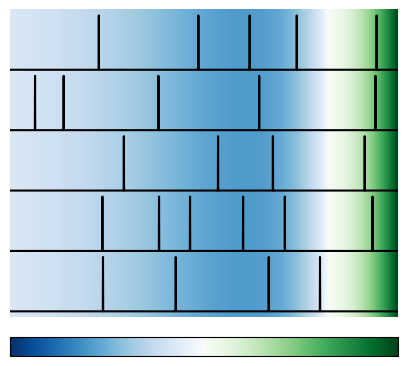

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
fig: plt.Figure
ax: plt.Axes

scale = 3.0
xlim = length*scale
ax.set_xlim(0, xlim)
ax.set_ylim(-0.1, 5)
ax.set_axis_off()

colors1 = plt.cm.Blues(np.linspace(0., 1, 128)[::-1])
colors2 = plt.cm.Greens(np.linspace(0, 1, 128))

# combine them and build a new colormap
colors = np.vstack((colors1, colors2))
mymap = mcolors.LinearSegmentedColormap.from_list('my_colormap', colors)

x = np.linspace(0, length, length)[::-1]
# y = -0.8714 * 0.9**x + 1.1816 * 0.85**x
y = comp_trac_diff(x)

im = ax.imshow([y], cmap=mymap, extent=(0, 1, 0, 1), transform=ax.transAxes, norm=mcolors.TwoSlopeNorm(vmin=y.min()-0.05, vcenter=0.0, vmax=y.max()))

num = 5
height = 0.9
np.random.seed(9)

xs = [draw_repeated(min=30, max=200, length=length, margin=0) for _ in range(num)]

for i, x in enumerate(xs):
    spikes = indices_to_spikes(x, length=length, scale=scale)
    spikes = spikes * 0.9 + i
    ax.plot(spikes, c="black")


cbar = fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.05) 
cbar.set_ticks([])

if save_plots:
    fig.savefig(dir_path + "colored_spikes.svg", bbox_inches='tight')

In [16]:
idx = 0
spikes = indices_to_spikes(xs[idx], length=length, scale=1.0)

In [17]:
trace_f = trace_over(spikes, beta_f)
trace_s = trace_over(spikes, beta_s)
trace_diff = gain_f * trace_f - gain_s * trace_s

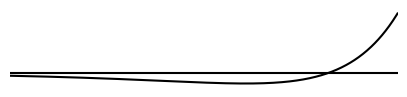

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(5, 1))
fig: plt.Figure
ax: plt.Axes
ax.set_xlim(0, length)
# ax.set_ylim(-0.1, 2.2)
ax.set_axis_off()
steps = 10
x = np.linspace(0, length, length)[::-1]
# y = -0.8714 * 0.9**x + 1.1816 * 0.85**x
y = comp_trac_diff(x)
ax.plot(x[::-1], y, c="black")
ax.plot(x[::-1], np.zeros_like(x), c="black")

if save_plots:
    fig.savefig(dir_path + "trace_kernel.svg", bbox_inches='tight')

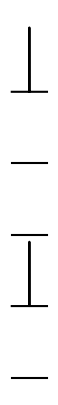

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(0.5, 5))
fig: plt.Figure
ax: plt.Axes
# ax.set_xlim(0, 10)
# ax.set_ylim(0, 10)
ax.set_axis_off()
steps = 10
x = np.linspace(0, 100, steps * 100)
dx1 = np.zeros_like(x) + 0
dx1[steps * 100 // 2] += 0 
dx2 = np.zeros_like(x) + 1
dx2[steps * 100 // 2] += 0.9
dx3 = np.zeros_like(x) + 2
dx3[steps * 100 // 2] += 0
dx4 = np.zeros_like(x) + 3
dx4[steps * 100 // 2] += 0
dx5 = np.zeros_like(x) + 4
dx5[steps * 100 // 2] += 0.9
ax.plot(dx1, c="black")
ax.plot(dx2, c="black")
ax.plot(dx3, c="black")
ax.plot(dx4, c="black")
ax.plot(dx5, c="black")

if save_plots:
    fig.savefig(dir_path + "spikes_dt.svg", bbox_inches='tight')

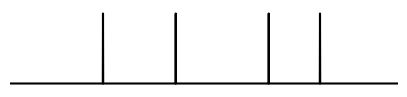

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(5, 1))
scale = 3.0
ax.set_xlim(0, length*scale)
ax.set_axis_off()
steps = 10

idx = 0
spikes = indices_to_spikes(xs[idx], length=length, scale=scale)


ax.plot(spikes, c="black")

if save_plots:
    fig.savefig(dir_path + "spikes.svg", bbox_inches='tight')

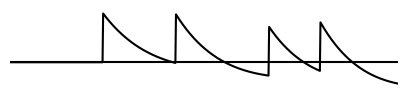

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(5, 1))
ax.set_xlim(0, length)
ax.set_axis_off()
steps = 10
x = np.linspace(0, length, length)[::-1]
y = comp_trac_diff(x)
ax.plot(x[::-1], trace_diff, c="black")
ax.plot(x[::-1], np.zeros_like(x), c="black")

if save_plots:
    fig.savefig(dir_path + "trace_diff.svg", bbox_inches='tight')

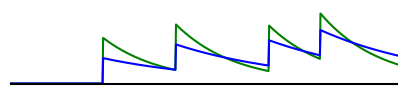

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(5, 1))
ax.set_xlim(0, length)
ax.set_axis_off()
steps = 10
x = np.linspace(0, length, length)[::-1]
y = comp_trac_diff(x)
ax.plot(x[::-1], gain_f * trace_f, c="green")
ax.plot(x[::-1], gain_s * trace_s, c="blue")
ax.plot(x[::-1], np.zeros_like(x), c="black")

if save_plots:
    fig.savefig(dir_path + "traces_fast_slow.svg", bbox_inches='tight')